In [2]:
#sayad alakbarov
#pset 4

In [ ]:
# question 1-a
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
college = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-College.csv")

college = college.rename(columns={"Unnamed: 0": "College"})
college.drop(columns=["College"], inplace=True)

college["Private"] = (college["Private"] == "Yes").astype(int)
y = college["Apps"]                   
X = college.drop(columns=["Apps"])     
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=37
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)      
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [ ]:
#question 1-b
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
ols = LinearRegression()
ols.fit(X_train, y_train)
y_pred = ols.predict(X_test)

mse_test = mean_squared_error(y_test, y_pred)
mse_test

1222954.038253454

In [6]:
#question1-b comment
#Using OLS on the training set,
#Test MSE = 1,222,954.04

Best M by CV: 16
CV MSE at best M: 1379942.5440


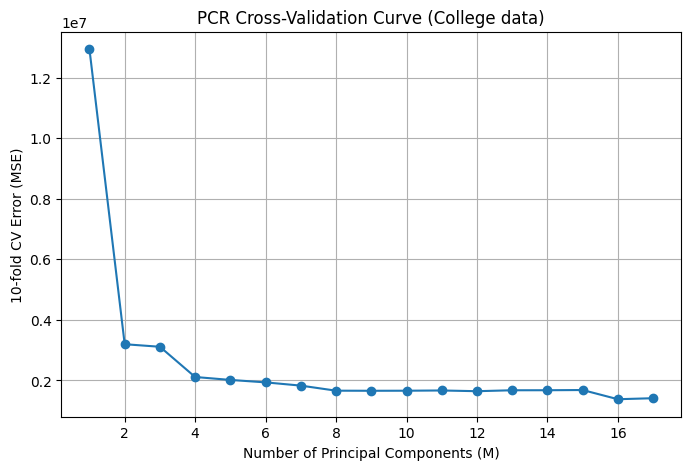

PCR Test MSE (using M = 16): 1487304.1279


In [ ]:
#question 1-c
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.decomposition import PCA

college = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-College.csv")
college = college.rename(columns={"Unnamed: 0": "College"})
college = college.drop(columns=["College"])

college["Private"] = (college["Private"] == "Yes").astype(int)

y_col = college["Apps"]
X_col = college.drop(columns=["Apps"])
X_col_train, X_col_test, y_col_train, y_col_test = train_test_split(
    X_col, y_col, test_size=0.5, random_state=37
)

scaler_col = StandardScaler()
X_col_train_scaled = scaler_col.fit_transform(X_col_train)
X_col_test_scaled = scaler_col.transform(X_col_test)

max_M = X_col_train_scaled.shape[1]
kf = KFold(n_splits=10, shuffle=True, random_state=1)

cv_errors = []

for M in range(1, max_M + 1):
    pca = PCA(n_components=M)
    X_train_pca = pca.fit_transform(X_col_train_scaled)

    mse_fold = []
    for train_idx, val_idx in kf.split(X_train_pca):
        X_tr, X_val = X_train_pca[train_idx], X_train_pca[val_idx]
        y_tr, y_val = y_col_train.iloc[train_idx], y_col_train.iloc[val_idx]

        model = LinearRegression()
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        mse_fold.append(mean_squared_error(y_val, preds))

    cv_errors.append(np.mean(mse_fold))

best_M = np.argmin(cv_errors) + 1
best_cv_mse = cv_errors[best_M - 1]
print(f"Best M by CV: {best_M}")
print(f"CV MSE at best M: {best_cv_mse:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, max_M + 1), cv_errors, marker='o')
plt.xlabel("Number of Principal Components (M)")
plt.ylabel("10-fold CV Error (MSE)")
plt.title("PCR Cross-Validation Curve (College data)")
plt.grid(True)
plt.show()

pca_final = PCA(n_components=best_M)
X_train_pca_final = pca_final.fit_transform(X_col_train_scaled)
X_test_pca_final = pca_final.transform(X_col_test_scaled)

pcr_final = LinearRegression()
pcr_final.fit(X_train_pca_final, y_col_train)

y_pred_pcr = pcr_final.predict(X_test_pca_final)
pcr_test_mse = mean_squared_error(y_col_test, y_pred_pcr)
print(f"PCR Test MSE (using M = {best_M}): {pcr_test_mse:.4f}")

In [ ]:
#question 1-c comment
# Best M chosen by cross-validation: 16 Cross-validated MSE at M = 16: 1,379,942.54
# Based on the elbow plot, the CV error drops steeply until around M ≈ 5, after which improvements become marginal. Thus, the “elbow method” selects M ≈ 5.
# Test MSE for the final PCR model (using M = 16): 1,487,304.13

Best M by CV: 9
CV MSE at best M: 1393525.1387675349


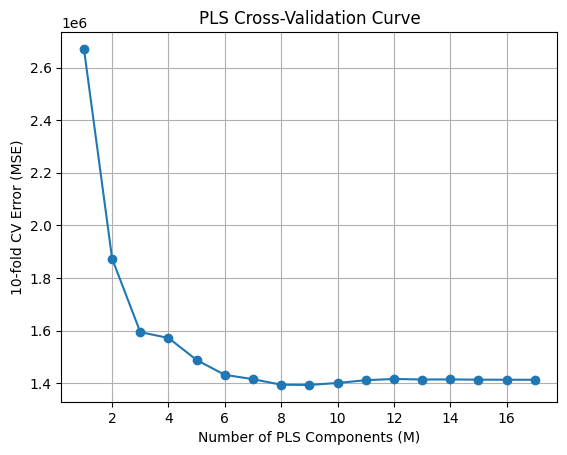

PLS Test MSE (using M = 9): 1300987.6972


In [ ]:
#question 1-d
from sklearn.cross_decomposition import PLSRegression
max_M = X_train_scaled.shape[1]
pls_cv_errors = []
kf = KFold(n_splits=10, shuffle=True, random_state=1)

for M in range(1, max_M + 1):
    mse_fold = []
    for train_idx, val_idx in kf.split(X_train_scaled):
        X_tr, X_val = X_train_scaled.iloc[train_idx], X_train_scaled.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        pls = PLSRegression(n_components=M)
        pls.fit(X_tr, y_tr)
        preds = pls.predict(X_val).ravel()
        mse_fold.append(mean_squared_error(y_val, preds))

    pls_cv_errors.append(np.mean(mse_fold))

best_pls_M = np.argmin(pls_cv_errors) + 1
best_pls_cv = pls_cv_errors[best_pls_M - 1]
print("Best M by CV:", best_pls_M)
print("CV MSE at best M:", best_pls_cv)

plt.plot(range(1, max_M + 1), pls_cv_errors, marker="o")
plt.xlabel("Number of PLS Components (M)")
plt.ylabel("10-fold CV Error (MSE)")
plt.title("PLS Cross-Validation Curve")
plt.grid(True)
plt.show()
pls_final = PLSRegression(n_components=best_pls_M)
pls_final.fit(X_train_scaled, y_train)

pls_test_pred = pls_final.predict(X_test_scaled).ravel()
pls_test_mse = mean_squared_error(y_test, pls_test_pred)
print("PLS Test MSE (using M = {}): {:.4f}".format(best_pls_M, pls_test_mse))

In [ ]:
# question 1-d comment

# Using 10-fold cross-validation (shuffle = True, random_state = 1):
# Best number of components by CV: M = 9 Corresponding CV MSE: 1,393,525.14
# From the PLS CV curve, the “elbow” occurs around M ≈ 4,since after ~4 components the CV error decreases much more slowly.
# Using the CV-selected number of components (M = 9), the PLS test MSE on the held-out test set is: 1,300,987.70

In [ ]:
#question 1-e
# Across all models (OLS, PCR, and PLS), the test MSEs are all on the order of 1.2–1.5 million.
# This indicates that while the models capture some structure in the predictors,the number of applications is still difficult to predict with very high accuracy. 
# There is substantial unexplained variability.
# OLS produced the lowest test MSE (≈ 1.22 million), performing slightly better than both PCR 
# (≈ 1.49 million) and PLS (≈ 1.30 million). This suggests that shrinking the predictor space 
# through dimensionality reduction does not improve predictive accuracy here—indeed, the full  set of predictors in OLS performs best.
# PCR and PLS reduce dimensionality, but their test errors were not dramatically different 
# from OLS. PLS performed better than PCR but still worse than OLS. Overall, the three methods achieve similar accuracy, and none significantly outperforms the others.

# In summary, the number of college applications is moderately predictable using the available 
# variables, but considerable noise remains, and differences in performance across the methods are relatively small.

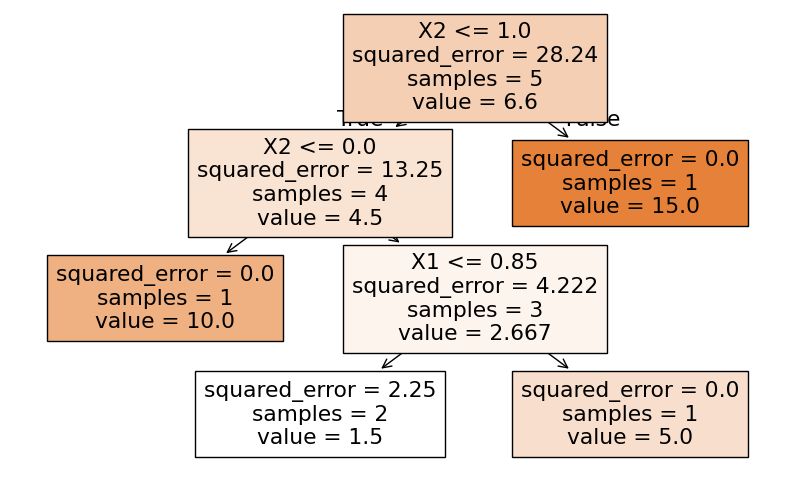

In [ ]:
#question 2-a
from sklearn import tree
# Points that land in each region:
# Region 1: X1 >= 1 → 5
# Region 2: X1 < 1, X2 >= 1 → 15
# Region 3: X1 < 0, X2 < 1 → 3
# Region 4: 0 ≤ X1 < 1, X2 < 0 → 10
# Region 5: 0 ≤ X1 < 1, 0 ≤ X2 < 1 → 0

X = np.array([
    [1.2, 0.5],     
    [0.5, 1.5],     
    [-0.5, 0.5],  
    [0.5, -0.5],   
    [0.5, 0.5]   
])

y = np.array([5, 15, 3, 10, 0])
model = tree.DecisionTreeRegressor(max_depth=3)
model.fit(X, y)

plt.figure(figsize=(10,6))
tree.plot_tree(model, feature_names=["X1", "X2"], filled=True)
plt.show()

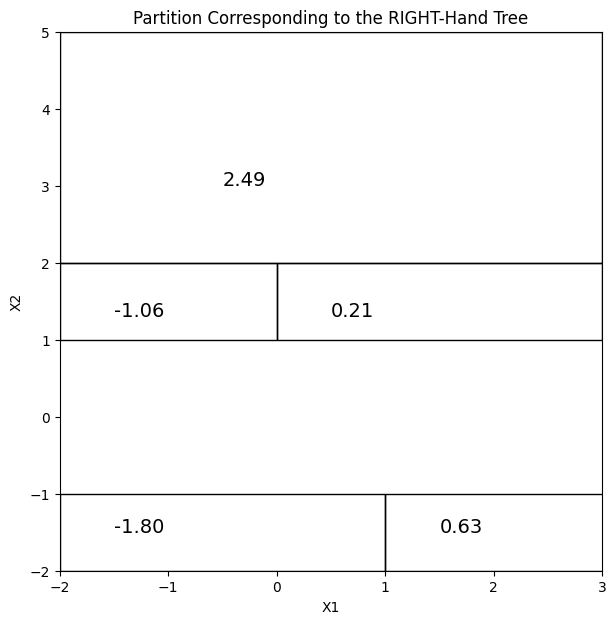

In [ ]:
# question 2 -b 
import matplotlib.patches as patches
fig, ax = plt.subplots(figsize=(7,7))
ax.add_patch(patches.Rectangle(( -2, -2), 3, 1, fill=False))
ax.text(-1.5, -1.5, "-1.80", fontsize=14)
ax.add_patch(patches.Rectangle((1, -2), 3, 1, fill=False))
ax.text(1.5, -1.5, "0.63", fontsize=14)
ax.add_patch(patches.Rectangle((-2, 1), 2, 1, fill=False))
ax.text(-1.5, 1.3, "-1.06", fontsize=14)
ax.add_patch(patches.Rectangle((0, 1), 3, 1, fill=False))
ax.text(0.5, 1.3, "0.21", fontsize=14)
ax.add_patch(patches.Rectangle((-2, 2), 5, 3, fill=False))
ax.text(-0.5, 3, "2.49", fontsize=14)

ax.set_xlim(-2, 3)
ax.set_ylim(-2, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("Partition Corresponding to the RIGHT-Hand Tree")
plt.grid(False)
plt.show()

In [ ]:
#question 3-a
from sklearn.model_selection import train_test_split
oj = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-OJ.csv")
oj_train, oj_test = train_test_split(
    oj,
    test_size=0.30,
    random_state=3
)

print(oj_train.shape)
print(oj_test.shape)

(749, 18)
(321, 18)


In [ ]:
# question 3-b
X_train = oj_train.drop(columns=["Purchase"])
X_test  = oj_test.drop(columns=["Purchase"])

X_train_dum = pd.get_dummies(X_train, drop_first=True)
X_test_dum  = pd.get_dummies(X_test,  drop_first=True)
X_train_dum, X_test_dum = X_train_dum.align(X_test_dum, join="left", axis=1, fill_value=0)

y_train = oj_train["Purchase"]

tree_full = DecisionTreeClassifier(random_state=2)
tree_full.fit(X_train_dum, y_train)
train_pred = tree_full.predict(X_train_dum)
train_error = 1 - accuracy_score(y_train, train_pred)
train_error

0.006675567423230944

In [25]:
# Training error rate = 0.00668

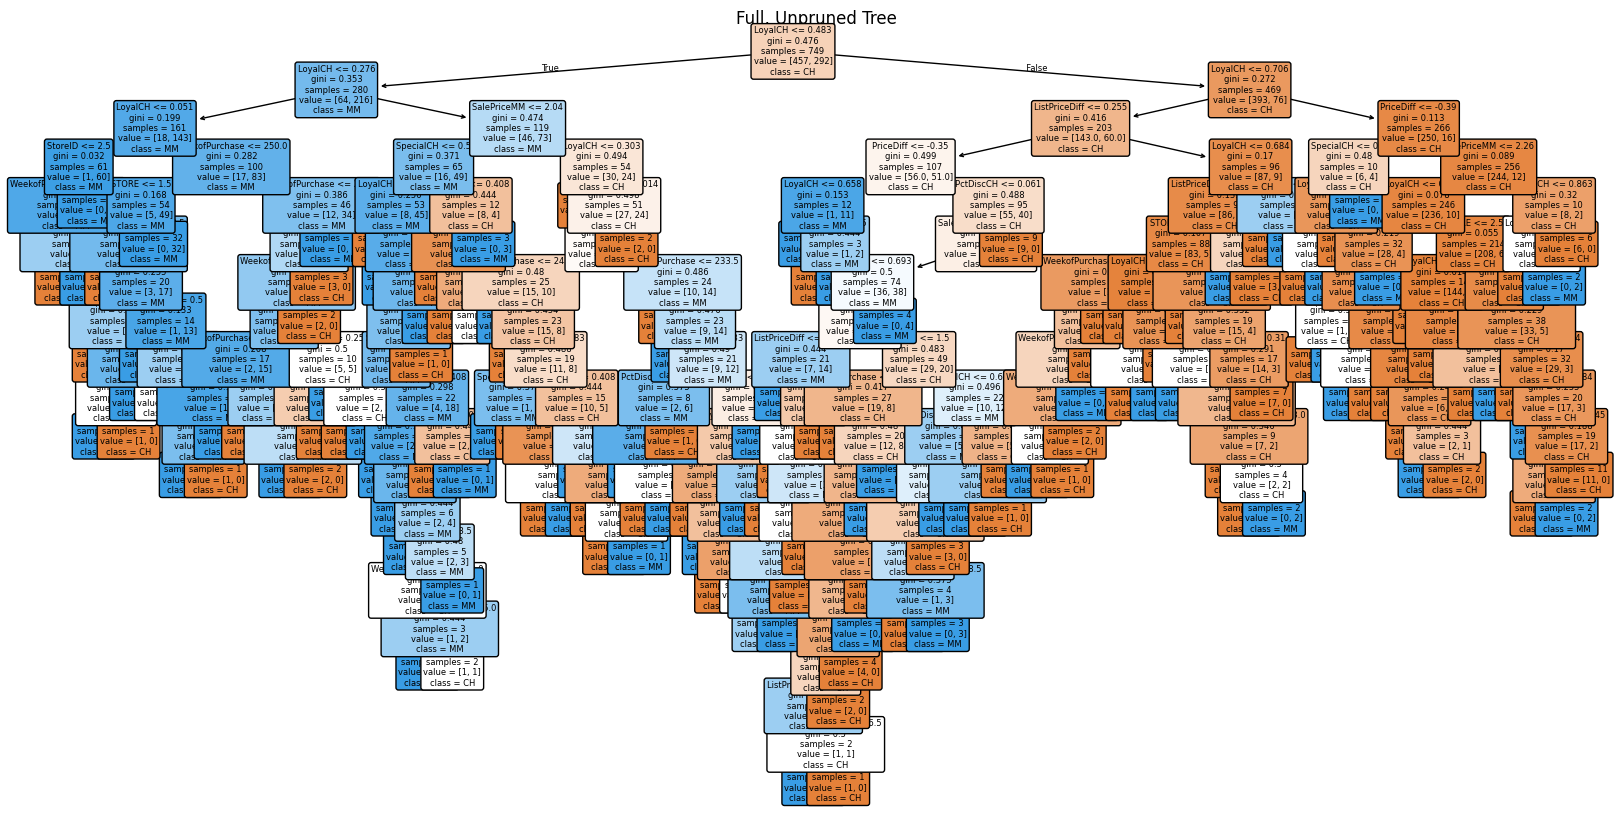

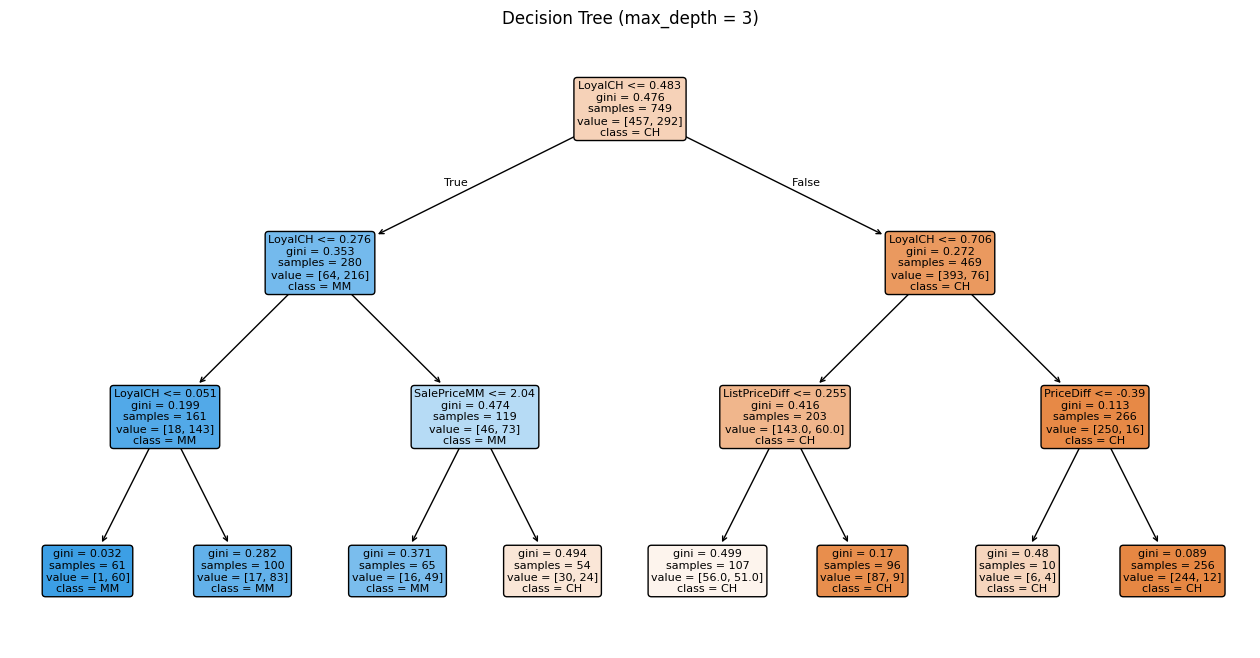

np.int64(8)

In [ ]:
#question 3-c
plt.figure(figsize=(20, 10))
tree.plot_tree(
    tree_full,
    feature_names=X_train_dum.columns,
    class_names=tree_full.classes_,
    filled=True,
    rounded=True,
    fontsize=6
)
plt.title("Full, Unpruned Tree")
plt.show()
tree_depth3 = DecisionTreeClassifier(max_depth=3, random_state=2)
tree_depth3.fit(X_train_dum, y_train)

plt.figure(figsize=(16, 8))
tree.plot_tree(
    tree_depth3,
    feature_names=X_train_dum.columns,
    class_names=tree_depth3.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree (max_depth = 3)")
plt.show()
tree_depth3.get_n_leaves()


In [ ]:
# question 3-c comment
# The full, unpruned tree produces an extremely large and messy plot with many layers of splits, confirming that a fully grown tree overfits heavily and is difficult to interpret.
# To obtain an interpretable tree, we fit a tree with max_depth = 3. This tree has 8 terminal nodes (leaves), as reported by tree_depth3.get_n_leaves().
# Interpretation of the *first* terminal node (leftmost leaf in the plot):
# Path to this node:
#   LoyalCH <= 0.483   
#   LoyalCH <= 0.276     
#   LoyalCH <= 0.051     
# This leaf contains:
# gini = 0.032 samples = 61
# class = MM (majority class) value = [1, 60]   (1 CH, 60 MM)
# Customers with very low loyalty to CH (LoyalCH <= 0.051) almost always purchase MM.
# In this region, 60 out of 61 training observations choose MM, so the model predicts
# MM with very high confidence. The gini index is extremely low (0.032), confirming that the node is almost perfectly pure.

In [ ]:
#question 3-d
from sklearn.metrics import confusion_matrix, accuracy_score
y_test = oj_test["Purchase"]
test_pred = tree_full.predict(X_test_dum)
cm = confusion_matrix(y_test, test_pred)
cm

array([[160,  36],
       [ 41,  84]])

In [ ]:

test_error = 1 - accuracy_score(y_test, test_pred)
test_error

0.23987538940809972

In [ ]:
#question 3-d comment
# Confusion matrix (rows = true class, columns = predicted class):
#            Predicted CH   Predicted MM
# True CH        160             36
# True MM         41             84
# Test error rate = 0.2399  (≈ 24%)
# So the fully grown tree, despite having a very low training error, misclassifies about 24% of the observations in the test set, indicating substantial overfitting.

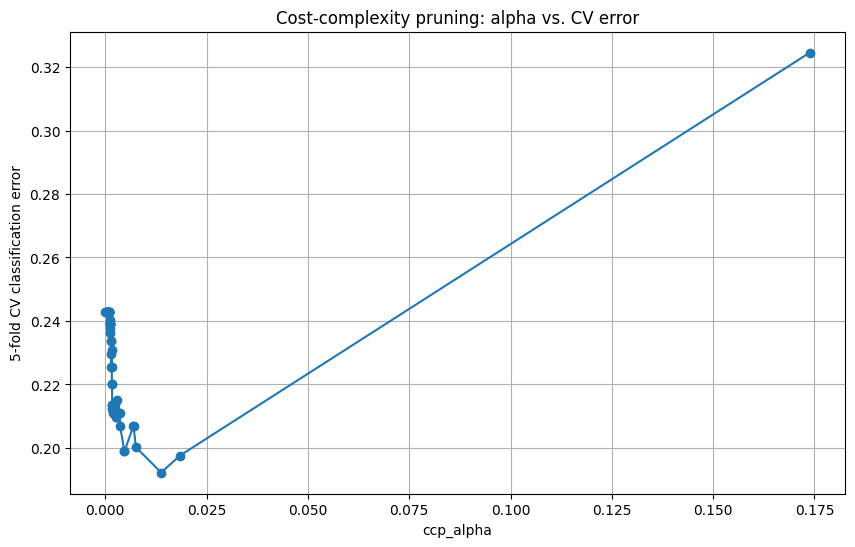

np.float64(0.01379269302194669)

In [ ]:
#question 3-e
path = tree_full.cost_complexity_pruning_path(X_train_dum, y_train)
ccp_alphas = path.ccp_alphas

cv_errors = []
kf = KFold(n_splits=5, shuffle=True, random_state=13)

for alpha in ccp_alphas:
    fold_errors = []
    for train_idx, val_idx in kf.split(X_train_dum):
        X_tr, X_val = X_train_dum.iloc[train_idx], X_train_dum.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        clf = DecisionTreeClassifier(random_state=2, ccp_alpha=alpha)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_val)
        fold_errors.append(1 - accuracy_score(y_val, preds))
    cv_errors.append(np.mean(fold_errors))
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, cv_errors, marker="o")
plt.xlabel("ccp_alpha")
plt.ylabel("5-fold CV classification error")
plt.title("Cost-complexity pruning: alpha vs. CV error")
plt.grid(True)
plt.show()
best_alpha = ccp_alphas[np.argmin(cv_errors)]
best_alpha

In [ ]:
# question 3-e comment
# The plot of ccp_alpha vs. 5-fold CV classification error shows a clear U-shaped pattern:
# small values of alpha lead to overfitting (higher error), very large alphas lead to oversimplified trees (also higher error), and the minimum occurs in between.
# The value of alpha that gives the lowest cross-validated classification error  ccp_alpha ≈ 0.0138
# This alpha corresponds to the optimal subtree for prediction under 5-fold CV (with shuffling and random_state = 13).


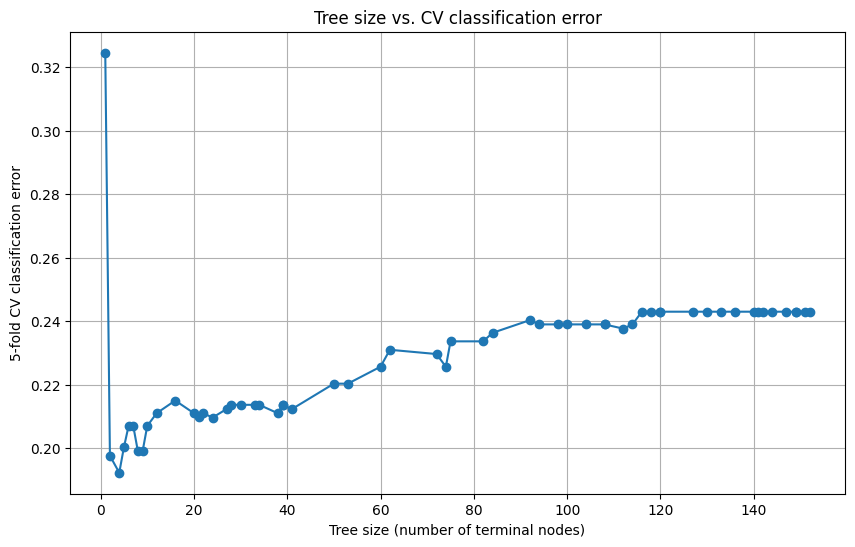

np.int64(4)

In [ ]:
#question 3-f
tree_sizes = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=2, ccp_alpha=alpha)
    clf.fit(X_train_dum, y_train)
    tree_sizes.append(clf.get_n_leaves())
plt.figure(figsize=(10, 6))
plt.plot(tree_sizes, cv_errors, marker="o")
plt.xlabel("Tree size (number of terminal nodes)")
plt.ylabel("5-fold CV classification error")
plt.title("Tree size vs. CV classification error")
plt.grid(True)
plt.show()
best_idx = np.argmin(cv_errors)
best_size = tree_sizes[best_idx]
best_size

In [ ]:
# question 3-f comment
# The plot of tree size (number of terminal nodes) versus 5-fold CV classification error shows that the CV error decreases sharply as we move from a very small tree to a
# moderately sized tree, and then begins to rise again as the tree becomes too large.
# The tree size that corresponds to the lowest CV classification error tree size = 4 terminal nodes.
# The cost-complexity parameter α directly controls the size of the tree.
# Larger α penalizes complexity more heavily, which forces the tree to prune more aggressively, resulting in a smaller tree. Small values of α allow the tree to grow
# larger, potentially overfitting. Because of this, α influences both tree size and the CV error rate: too much pruning (large α) underfits, while too little pruning
# (small α) overfits. The optimal α strikes a balance between these effects and produces the tree with the lowest CV error.

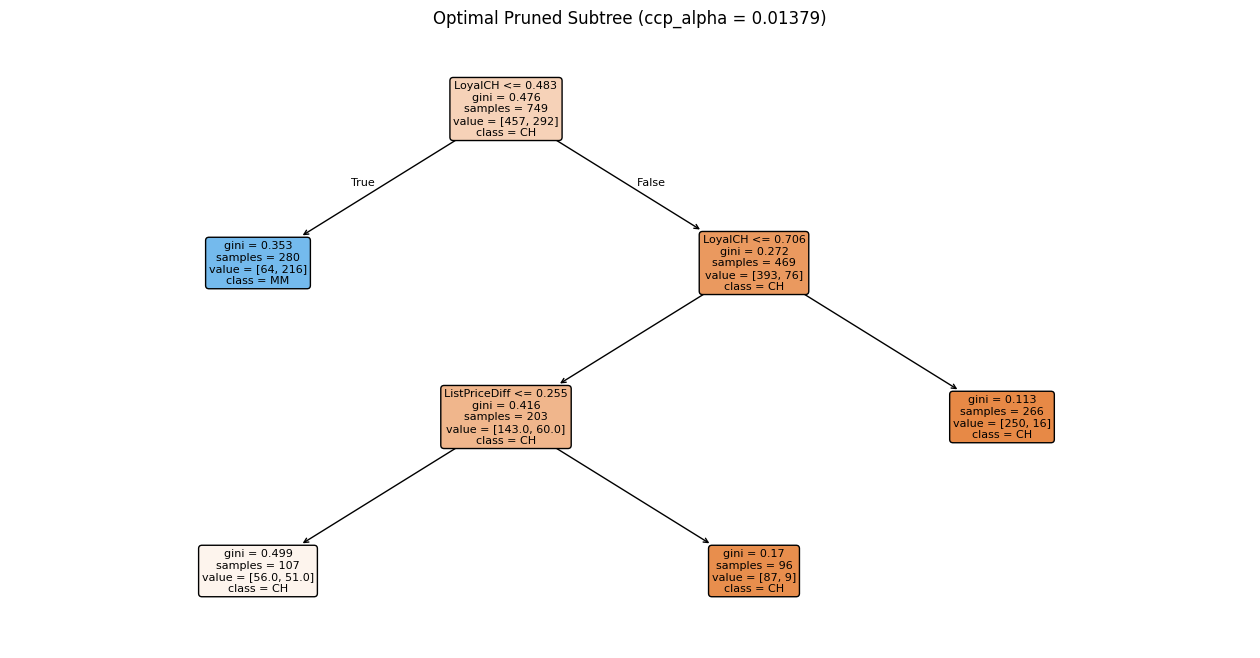

In [ ]:
#question 1-g

optimal_tree = DecisionTreeClassifier(
    random_state=2,
    ccp_alpha=best_alpha 
)
optimal_tree.fit(X_train_dum, y_train)

plt.figure(figsize=(16, 8))
tree.plot_tree(
    optimal_tree,
    feature_names=X_train_dum.columns,
    class_names=optimal_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title(f"Optimal Pruned Subtree (ccp_alpha = {best_alpha:.5f})")
plt.show()

In [37]:
#question 1-h
train_pred_pruned = optimal_tree.predict(X_train_dum)
train_error_pruned = 1 - accuracy_score(y_train, train_pred_pruned)
train_error_pruned

0.1869158878504673

In [38]:
#question 1-i
test_pred_pruned = optimal_tree.predict(X_test_dum)
test_error_pruned = 1 - accuracy_score(y_test, test_pred_pruned)
test_error_pruned

0.19937694704049846

In [ ]:
#question 3-h comment
#The unpruned tree has a training error rate of approximately 0.0067, while the pruned tree has a training error rate of approximately 0.1869.
# The pruned tree has the higher training error rate.
# This is expected because pruning simplifies the model and removes splits that were perfectly fitting the training data (i.e., overfitting).
# A simpler tree cannot memorize the training data as well as a fully grown tree, so its training error is higher.

In [ ]:
#question 3-i comment
# The unpruned tree has a test error rate of about 0.2399, while the pruned tree has a test error rate of about 0.1994.
# The unpruned (full) tree has the higher test error rate.
# This occurs because the unpruned tree severely overfits the training data, it captures noise and irrelevant splits, which hurts generalization.
# The pruned tree is smaller and less complex, so it generalizes better and achieves a lower test error on unseen data.